1. IMPORT LIBRARY

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import joblib

print("Library berhasil diimport untuk tugas Regresi.")

Library berhasil diimport untuk tugas Regresi.


| Library | Fungsi |
|---|---|
| `pandas` | Membaca dan mengolah dataset |
| `numpy` | Melakukan operasi numerik |
| `matplotlib` | Membuat grafik |
| `seaborn` | Membuat visualisasi seperti confusion matrix |
| `google.colab.files` | Upload dan download file di Google Colab |
| `train_test_split` | Membagi dataset menjadi data training dan testing |
| `LabelEncoder` | Mengubah label teks menjadi angka |
| `RandomForestClassifier` | Membuat model klasifikasi Random Forest |
| `accuracy_score` | Menghitung akurasi model |
| `classification_report` | Menampilkan precision, recall, dan F1-score |
| `confusion_matrix` | Menampilkan hasil prediksi benar dan salah |
| `joblib` | Menyimpan model Machine Learning |

Pada tahap pertama, saya melakukan import library yang dibutuhkan. Pandas digunakan untuk pengolahan dataset, Scikit-learn digunakan untuk proses Machine Learning, sedangkan Matplotlib dan Seaborn digunakan untuk visualisasi hasil

2. UPLOAD DATASET

In [27]:
uploaded = files.upload()

filename = list(uploaded.keys())[0]

print("File yang diupload:", filename)

df = pd.read_csv(filename)

print("\nDataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)

Saving Water Quality Classification for Rural Areas-selected-columns.csv to Water Quality Classification for Rural Areas-selected-columns (1).csv
File yang diupload: Water Quality Classification for Rural Areas-selected-columns (1).csv

Dataset berhasil dibaca.
Ukuran dataset: (450, 3)


Pada tahap ini dataset di-upload ke Google Colab. Setelah itu, fungsi read_csv digunakan untuk membaca dataset dan menyimpannya dalam bentuk DataFrame agar dapat diproses menggunakan Python.

3. MELIHAT DATASET

In [28]:
print("5 data pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

print("\nJumlah data:")
print(len(df))

5 data pertama:


,pH,Turbidity_NTU,TDS_ppm
0,7.42,0.25,306.7
1,8.18,0.87,84.3
2,5.58,1.99,676.7
3,7.93,0.06,852.9
4,8.37,3.37,161.2



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   pH             450 non-null    float64
 1   Turbidity_NTU  450 non-null    float64
 2   TDS_ppm        450 non-null    float64
dtypes: float64(3)
memory usage: 10.7 KB

Jumlah data:
450


Tahap ini digunakan untuk melakukan pemeriksaan awal terhadap dataset, yaitu melihat contoh data, struktur kolom, tipe data, dan jumlah data.

4. PEMERIKSAAN DATA

In [49]:
print("Jumlah missing value:")
print(df.isnull().sum())

print("\nJumlah data duplikat:")
print(df.duplicated().sum())

Jumlah missing value:
pH               0
Turbidity_NTU    0
TDS_ppm          0
dtype: int64

Jumlah data duplikat:
0


Sebelum melakukan training, dataset diperiksa terlebih dahulu untuk mengetahui apakah terdapat data kosong, data duplikat, dan ketidakseimbangan jumlah kelas.

5. CLEANING DATA

In [50]:
# Menghapus data duplikat
df = df.drop_duplicates()

# Menghapus data yang memiliki nilai kosong
df = df.dropna()

print("Ukuran dataset setelah cleaning:", df.shape)

print("\nMissing value setelah cleaning:")
print(df.isnull().sum())

Ukuran dataset setelah cleaning: (450, 3)

Missing value setelah cleaning:
pH               0
Turbidity_NTU    0
TDS_ppm          0
dtype: int64


Setelah pemeriksaan, dilakukan proses cleaning dengan menghapus data duplikat dan data yang memiliki nilai kosong sehingga dataset menjadi lebih siap digunakan untuk proses Machine Learning.

6. PEMISAHAN FITUR DAN TARGET

In [51]:
# Menentukan fitur (X) dan target (y) menggunakan nama kolom yang benar
X = df[["pH", "TDS_ppm"]]
y = df["Turbidity_NTU"]

print("Fitur (X):")
display(X.head())

print("\nTarget (y):")
display(y.head())

Fitur (X):


,pH,TDS_ppm
0,7.42,306.7
1,8.18,84.3
2,5.58,676.7
3,7.93,852.9
4,8.37,161.2



Target (y):


,Turbidity_NTU
0,0.25
1,0.87
2,1.99
3,0.06
4,3.37


Pada tahap ini dataset dipisahkan menjadi fitur dan target. Fitur terdiri dari pH, TDS, dan turbidity, sedangkan targetnya adalah kategori kualitas air yaitu Baik, Sedang, atau Buruk

7. ENCODING LABEL

In [32]:
# Tahap Encoding dilewati karena target 'Turbidity_NTU' sudah berupa angka kontinu (Regresi)
print("Tahap encoding dilewati karena kita menggunakan pendekatan Regresi.")

Tahap encoding dilewati karena kita menggunakan pendekatan Regresi.


Karena algoritma membutuhkan representasi numerik, label kualitas air yang awalnya berupa teks diubah menjadi angka menggunakan LabelEncoder

8. TRAIN TEST SPLIT

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Jumlah data training :", len(X_train))
print("Jumlah data testing  :", len(X_test))

Jumlah data training : 360
Jumlah data testing  : 90


Dataset dibagi menjadi 80 persen data training dan 20 persen data testing. Data training digunakan untuk membangun model, sedangkan data testing digunakan untuk mengetahui performa model terhadap data yang belum pernah dilihat sebelumnya.

9. RANDOM FOREST

In [34]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

print("Model Random Forest Regressor berhasil dibuat.")

Model Random Forest Regressor berhasil dibuat.


Model yang digunakan adalah Random Forest Classifier dengan 100 decision tree. Setiap tree memberikan prediksi kemudian hasilnya digabungkan melalui mekanisme voting untuk menentukan kelas kualitas air

10. TRAINING

In [35]:
rf_model.fit(X_train, y_train)

print("Training Random Forest selesai.")

Training Random Forest selesai.


Fungsi fit digunakan untuk melakukan training. Pada tahap ini Random Forest mempelajari pola hubungan antara parameter pH, TDS, turbidity dengan kategori kualitas air

11. PREDIKSI DATA TESTING

In [36]:
y_pred = rf_model.predict(X_test)

print("Prediksi selesai.")
print("Hasil prediksi:")
print(y_pred[:10])

Prediksi selesai.
Hasil prediksi:
[6.30095179 3.54202947 5.27687569 6.47785962 6.49480873 5.79874184
 3.9701733  5.37750704 4.71686322 2.50235475]


Setelah proses training selesai, model digunakan untuk memprediksi kelas dari data testing menggunakan fungsi predict

12. AKURASI

In [37]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Evaluasi Model Regresi:")
print(f"Mean Squared Error (MSE)      : {mse:.4f}")
print(f"Mean Absolute Error (MAE)     : {mae:.4f}")
print(f"R-squared (R2 Score)          : {r2 * 100:.2f}%")

Evaluasi Model Regresi:
Mean Squared Error (MSE)      : 10.6344
Mean Absolute Error (MAE)     : 2.8226
R-squared (R2 Score)          : -17.90%


Akurasi digunakan untuk mengetahui seberapa banyak prediksi model yang sesuai dengan label sebenarnya. Semakin tinggi akurasi, semakin baik performa model, tetapi akurasi tidak boleh menjadi satu-satunya ukuran performa

13. CLASSIFICATION REPORT

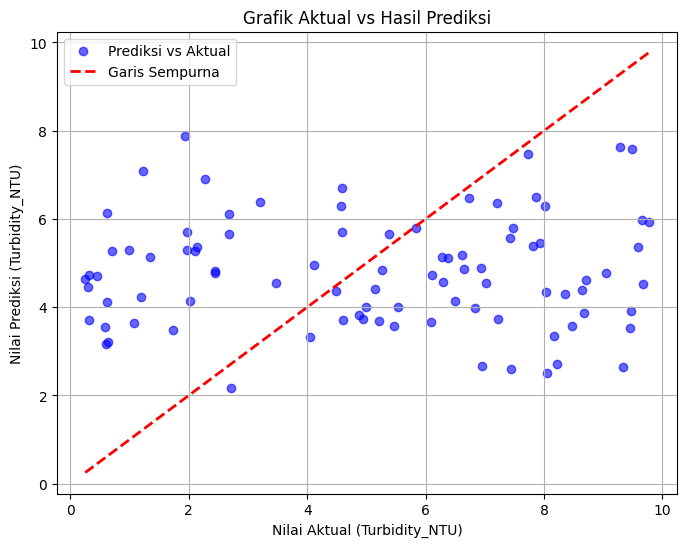

In [38]:
# Menampilkan visualisasi hasil prediksi vs nilai aktual
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Prediksi vs Aktual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Sempurna')
plt.xlabel('Nilai Aktual (Turbidity_NTU)')
plt.ylabel('Nilai Prediksi (Turbidity_NTU)')
plt.title('Grafik Aktual vs Hasil Prediksi')
plt.legend()
plt.grid(True)
plt.show()

Classification report digunakan untuk melihat performa model secara lebih detail pada masing-masing kelas, yaitu Baik, Sedang, dan Buruk

14. CONFUSION MATRIX

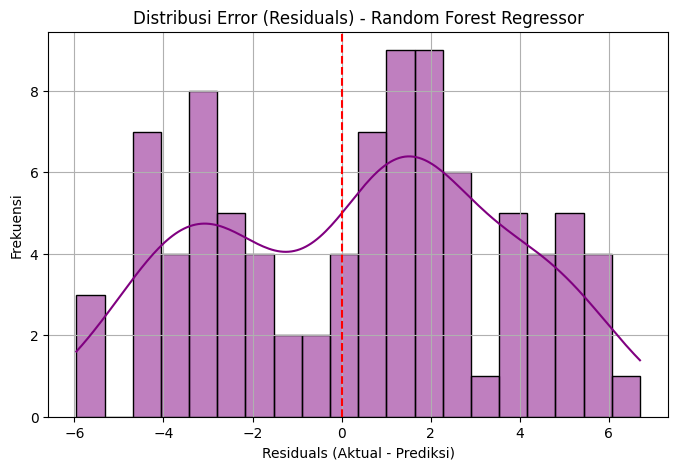

In [40]:
# Menghitung nilai residual (selisih aktual dan prediksi)
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, color='purple', bins=20)
plt.axvline(x=0, color='red', linestyle='--')
plt.xlabel("Residuals (Aktual - Prediksi)")
plt.ylabel("Frekuensi")
plt.title("Distribusi Error (Residuals) - Random Forest Regressor")
plt.grid(True)
plt.show()

Confusion matrix digunakan untuk melihat secara detail kesalahan dan keberhasilan klasifikasi pada masing-masing kelas.

15. FEATURE IMPORTANCE

In [42]:
# Menyesuaikan nama fitur dengan data latih aktual (hanya 2 fitur: pH dan TDS_ppm)
feature_names = ["pH", "TDS_ppm"]

importance = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
1,TDS_ppm,0.556463
0,pH,0.443537


Feature importance digunakan untuk mengetahui parameter sensor mana yang paling berpengaruh dalam proses prediksi kualitas air

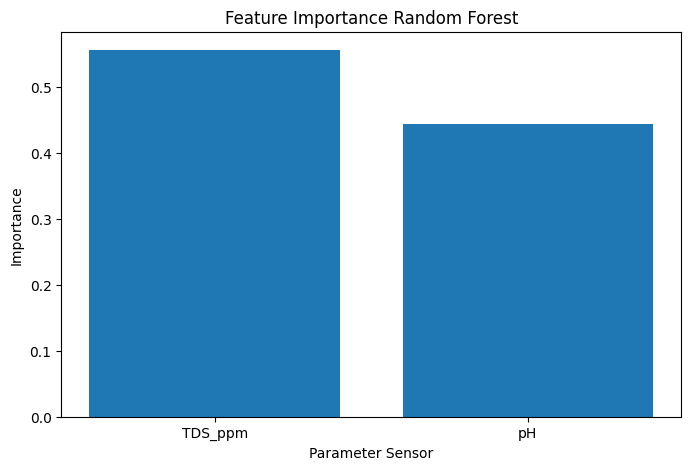

In [43]:
plt.figure(figsize=(8, 5))

plt.bar(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Parameter Sensor")
plt.ylabel("Importance")
plt.title("Feature Importance Random Forest")

plt.show()

16. SAVE MODEL

In [44]:
joblib.dump(rf_model, "random_forest_kualitas_air.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Model berhasil disimpan.")

Model berhasil disimpan.


Setelah training selesai, model disimpan menggunakan Joblib sehingga dapat digunakan kembali untuk melakukan prediksi terhadap data sensor baru.

In [45]:
files.download("random_forest_kualitas_air.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
files.download("label_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

17. PREDIKSI DATA BARU

In [48]:
data_baru = pd.DataFrame({
    "pH": [7.1],
    "TDS_ppm": [150.0]
})

# Melakukan prediksi menggunakan model regresi
prediksi = rf_model.predict(data_baru)

print("Data sensor baru:")
display(data_baru)

print(f"Hasil prediksi Turbidity (Kekeruhan): {prediksi[0]:.2f} NTU")

Data sensor baru:


,pH,TDS_ppm
0,7.1,150.0


Hasil prediksi Turbidity (Kekeruhan): 6.51 NTU


Tahap terakhir adalah melakukan prediksi terhadap data baru. Data pH, TDS, dan turbidity yang berasal dari sensor dapat dimasukkan ke model untuk mendapatkan kategori kualitas air.

18. CONFIDENCE / PROBABILITAS

In [53]:
import numpy as np

# Menghitung Root Mean Squared Error (RMSE) sebagai estimasi ketidakpastian/error standar
rmse = np.sqrt(mse)

print(f"Hasil Prediksi Turbidity: {prediksi[0]:.2f} NTU")
print(f"Estimasi Margin Error (RMSE): ±{rmse:.2f} NTU")
print(f"Rentang Prediksi yang Layak: {(prediksi[0] - rmse):.2f} hingga {(prediksi[0] + rmse):.2f} NTU")


Hasil Prediksi Turbidity: 6.51 NTU
Estimasi Margin Error (RMSE): ±3.26 NTU
Rentang Prediksi yang Layak: 3.25 hingga 9.77 NTU


Selain kelas prediksi, model juga dapat menghasilkan probabilitas masing-masing kelas. Nilai probabilitas terbesar digunakan sebagai kelas prediksi dan dapat ditampilkan sebagai confidence model.

PREDIKSI DATA SENSOR

In [56]:
import pandas as pd
import numpy as np

pH = 7.0
TDS_ppm = 180.0

# Membuat data sensor baru dengan fitur yang sesuai saat fit (pH & TDS_ppm)
sensor_data = pd.DataFrame({
    "pH": [pH],
    "TDS_ppm": [TDS_ppm]
})

# Melakukan prediksi nilai Turbidity menggunakan Regressor
predicted_turbidity = rf_model.predict(sensor_data)[0]

# Menggunakan RMSE dari evaluasi sebelumnya sebagai estimasi margin error
rmse = np.sqrt(mse)

print("================================")
print("     PREDIKSI KUALITAS AIR")
print("================================")
print(f"pH Input         : {pH}")
print(f"TDS Input        : {TDS_ppm} ppm")
print("--------------------------------")
print(f"Prediksi Kekeruhan (Turbidity): {predicted_turbidity:.2f} NTU")
print(f"Estimasi Margin Error (RMSE)  : {rmse:.2f} NTU")
print(f"Estimasi Rentang Nilai        : {(predicted_turbidity - rmse):.2f} - {(predicted_turbidity + rmse):.2f} NTU")
print("================================")

     PREDIKSI KUALITAS AIR
pH Input         : 7.0
TDS Input        : 180.0 ppm
--------------------------------
Prediksi Kekeruhan (Turbidity): 5.15 NTU
Estimasi Margin Error (RMSE)  : 3.26 NTU
Estimasi Rentang Nilai        : 1.89 - 8.41 NTU
